Import necessary pacakages and read data

In [76]:
import geopandas as gpd
import pandas as pd
from standard_distance import standard_distance
import math
import statsmodels as sm
import numpy as np

# change this as needed (i don't know why it doesn't take relative paths and I'm too tired to look into it).
# change these two as needed.
in_species = "all_camels"
out_species = "all_camels"

file_path = f"c:\\Users\\vladu\\OneDrive\\Desktop\\geotracking_camelids_NINO_project\\map_project\\inputs\\camel_data\\{in_species}.shp"

data = gpd.read_file(file_path)


View a sample

In [77]:
data.head()



,id,species_or,species_re,hybrid?,other_name,domestic_s,evidence_t,primary_so,source_oth,NISP_.,...,date_old,date_young,date_other,site,reference,comments,lat,long,CRS,geometry
0,53,Camelus bactrianus,Camelus bactrianus,False,NaN,domestic,faunal remains,NaN,NaN,73.0,...,1600.0,1799.0,17th-18th centuries CE,Agighiol,"Bălăşescu, A., 2014. Camels in Romania. Anthro...","2 specimens radiocarbon dated, but they don't ...",45.03,28.87,EPSG:4326,POINT (2372039.311 5470065.991)
1,54,Camelus dromedarius,Camelus dromedarius,False,NaN,domestic,faunal remains,NaN,NaN,1.0,...,1600.0,1799.0,17th-18th centuries CE,Agighiol,"Bălăşescu, A., 2014. Camels in Romania. Anthro...","2 specimens radiocarbon dated, but they don't ...",45.03,28.87,EPSG:4326,POINT (2372039.311 5470065.991)
2,55,hybrid,Camelus sp.,True,C. bactrianus x C. dromedarius hybrid,domestic,faunal remains,NaN,NaN,1.0,...,1600.0,1799.0,17th-18th centuries CE,Agighiol,"Bălăşescu, A., 2014. Camels in Romania. Anthro...","2 specimens radiocarbon dated, but they don't ...",45.03,28.87,EPSG:4326,POINT (2372039.311 5470065.991)
3,56,Camelus sp.,Camelus spp.,False,NaN,domestic,faunal remains,NaN,NaN,80.0,...,1600.0,1799.0,17th-18th centuries CE,Agighiol,"Bălăşescu, A., 2014. Camels in Romania. Anthro...",NaN,45.03,28.87,EPSG:4326,POINT (2372039.311 5470065.991)
4,58,Camelus bactrianus,Camelus bactrianus,False,NaN,domestic,faunal remains,NaN,"Gheorghiu and Haimovici (1965), Stefan et al. ...",1.0,...,800.0,1199.0,9th-12th centuries CE,Garvan-Dinogetia,"Bălăşescu, A., 2014. Camels in Romania. Anthro...",NaN,45.37,28.13,EPSG:4326,POINT (2305595.01 5506244.818)


Visual inspection + get geometry + get CRS

Point
EPSG:8857


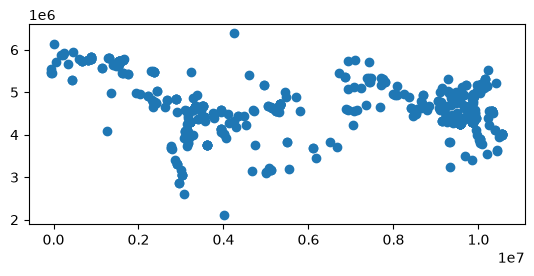

In [78]:
data.plot()
print(data.geom_type[0])
print(data.crs)
#coords = data.get_coordinates().to_numpy()


Only select valid coordinates (in this case with known years and with existing coordinates).

In [79]:
# Uncomment below if both conditions are needed.
# valid_data = data[data["date_old"].notnull() & data["lat"].notnull()]

valid_data = data[data["lat"].notnull()]

# Quick inspection to see how many points were dropped.
print(len(valid_data))
print(len(data))


522
522


Determine filter for additive selection (keep adding to selection based on new filter element). Also export the filter vector as csv if I want to join it to another shapefile later.

In [80]:
# This is for years for additive selection. Uncomment as necessary.
# # Pick which column becomes the filter.
# filter_column = "date_old"
# # Then make and sort the filter.
# filter_vector = sorted(valid_data[filter_column].dropna().unique())

# This is to get bandwidths for evidence_type
filter_column = "evidence_t"
filter_vector = sorted(valid_data[filter_column].dropna().unique())

# Initialise the filter dataframe as a dictionary first.
filter_dataframe = {
  "int_id" : range(1, len(filter_vector) + 1),
  "filter" : filter_vector,
}

# Then save it as dataframe and export to csv.
df = pd.DataFrame(filter_dataframe)
df
# df.to_csv(
#     rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\inputs\camel_data\{out_species}_years.csv"
# )
df.to_csv(fr"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\inputs\camel_data\{out_species}_evidence_types.csv")

Initialise output with the same structure as input and initialise a counter to use in file naming

In [81]:
output = valid_data.iloc[0:0]  # empty dataframe with same columns

counter = 1 # to keep track of which iteration it's on in the loop below.

bandwidth = [] # results list for the bandwidth calculated below.


Then just loop over elements in the filter and keep adding and saving the current output from each iteration. It also expands the bandwidth results list.

In [82]:
# Quick funtion for median distance from mean center to all points.
def median_distance(point, shapefile):

    # Calculate distance between center point and all other points in shapefile.
    shapefile["distance"] = shapefile.geometry.distance(point)

    median_distance = shapefile["distance"].median()

    return median_distance  # returns a float.


for item in filter_vector:
    tmp_selection = valid_data[
        valid_data[filter_column] == item
    ]  # termporary selection from the initial geodataframe.

    # add
    output = pd.concat([output, tmp_selection], ignore_index=True)
    output = gpd.GeoDataFrame(output, geometry="geometry", crs=valid_data.crs)

    # Uncomment below if need to export each iteration shapefile.
    # Leave commented out if you only need bandwidths.
    # output.to_file(
    #     rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\inputs\camel_data\{out_species}_splits\{out_species}_{counter}.shp",
    #     driver="ESRI Shapefile",
    # )

    n, sd, mid_point = standard_distance(output)
    dm = median_distance(mid_point, output)
    current_bandwidth = 0.9 * min(sd, math.sqrt(1 / math.log(2)) * dm) * n**-0.2

    bandwidth.append((n, sd, dm, current_bandwidth))

    output = valid_data.iloc[0:0]  # reinitialise empty dataframe with same columns

    counter += 1

bandwidth = pd.DataFrame(bandwidth, columns=["n", "sd", "dm", "bandwidth"])
# Change file paths as needed (just uncomment).
# bandwidth.to_csv(
#     rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\inputs\camel_data\{out_species}_bandwidth.csv"
# )

bandwidth.to_csv(
    rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\inputs\camel_data\{out_species}_evidence_t_bandwidth.csv"
)

print(counter-1)

4
